# Week 1: RUL labels, what wear looks like, and the mean baseline

Same steps as `src/02_week1.py`, with explanations. Both use the shared helpers in `src/cmapss.py`, so a fix there fixes both.

**Goal:** predict *Remaining Useful Life* (RUL), meaning how many flight cycles an engine has left before it fails, from its sensor readings. Dataset: NASA C-MAPSS, subset FD001.

In [1]:
import sys
sys.path.insert(0, '../src')   # let the notebook find our helper file in src/
%matplotlib inline
from cmapss import (load_train, constant_columns, sensor_correlations,
                    plot_wear, load_test_last_rows, rmse)

## Step 1: Load the training data and add RUL labels

A model learns from examples *with the answer attached* (the **label**), like flashcards. Training engines run all the way to failure, so we can compute the answer for every row:

**RUL = (engine's last cycle) − (current cycle)**. On the final flight, RUL = 0.

In [2]:
train = load_train()
print(train.shape)
train[train.unit == 1][['unit', 'cycle', 's11', 's12', 'RUL']].tail()

(20631, 27)


,unit,cycle,s11,s12,RUL
187,1,188,48.00,519.79,4
188,1,189,48.08,519.58,3
189,1,190,48.33,520.04,2
190,1,191,48.15,519.57,1
191,1,192,48.25,520.08,0


Engine 1 lasted 192 cycles, so its RUL counts down to 0 at cycle 192. Lifetimes vary a lot across engines:

In [3]:
train.groupby('unit').cycle.max().describe()[['min', 'mean', 'max']]

min     128.00
mean    206.31
max     362.00
Name: cycle, dtype: float64

## Step 2: Which sensors carry information?

A sensor that never changes can't tell a new engine from a worn one, so we drop it. **Correlation** (−1 to +1) measures how closely a sensor rises or falls with RUL.

In [4]:
const = constant_columns(train)
print('Constant (dropped):', const)
sensor_correlations(train).round(3)

Constant (dropped): ['op3', 's1', 's5', 's10', 's16', 's18', 's19']


s11   -0.696
s4    -0.679
s12    0.672
s7     0.657
s15   -0.643
s21    0.636
s20    0.629
s2    -0.606
s17   -0.606
s3    -0.585
s8    -0.564
s13   -0.563
s9    -0.390
s14   -0.307
s6    -0.128
dtype: float64

## Step 3: What wearing out looks like

x-axis = cycles until failure, so every engine's failure lines up at 0 on the right.

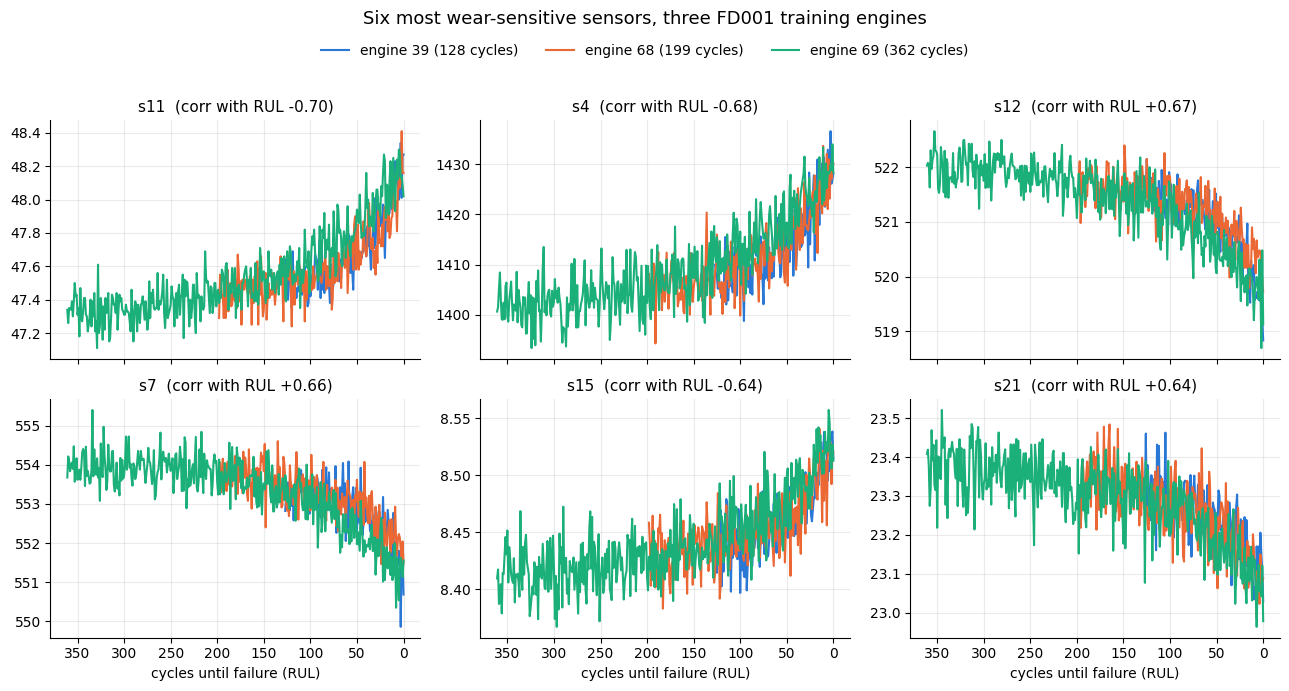

In [5]:
fig = plot_wear(train)

**Reading the plot:** sensors are flat and noisy while the engine is healthy, then bend sharply in roughly the last 100 cycles. All three engines (128, 199, 362 cycles long) follow the same shape near failure, so the sensors track *closeness to failure*, not age. Early in life, though, 300 vs 150 cycles left look almost the same, which is why we'll clip RUL at 125 in Week 3.

## Step 4: Mean-guess baseline

The dumbest reasonable model: guess the average training RUL for every test engine. We score only the **last row of each test engine** against `RUL_FD001.txt`, using **RMSE**, roughly "how many cycles off we typically are" (lower is better).

The guess uses *training data only*. Choosing it with test answers would be **data leakage**.

In [6]:
mean_rul = train.RUL.mean()
test_last = load_test_last_rows()
score = rmse(test_last.RUL, [mean_rul] * len(test_last))
print(f'Guess for every engine: {mean_rul:.1f} cycles')
print(f'True test RUL: average {test_last.RUL.mean():.1f}, range {test_last.RUL.min()}-{test_last.RUL.max()}')
print(f'Mean-guess baseline RMSE: {score:.2f} cycles')

Guess for every engine: 107.8 cycles
True test RUL: average 75.5, range 7-145
Mean-guess baseline RMSE: 52.62 cycles


**Result: RMSE ≈ 52.6.** This is the number every real model has to beat. The guess (107.8) is too high because training rows include each engine's whole healthy life, while test engines were cut off partway (true average 75.5).